# 05 · Previsões com o modelo vigente e comparação entre ciclos

O modelo vigente é carregado do armazenamento persistente **com** o pré-processamento e as features eleitas (tudo no mesmo `Pipeline`). As previsões são feitas para os clientes da **próxima campanha**: o lote que ainda não chegou ao pipeline e, portanto, não participou da escolha do modelo.

**Política de negócio:** o banco liga para os 20% de clientes com maior probabilidade de contratar.

In [1]:
import os, sys, warnings
from pathlib import Path
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
warnings.filterwarnings("ignore", category=UserWarning)
# Localiza a raiz do repositório e torna o pacote src importável
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.utils import carregar_config, configurar_mlflow, ler_contexto, atualizar_contexto, tags_ciclo, caminho, salvar_json
cfg = carregar_config()
pd.set_option("display.width", 160)

In [2]:
from src.promocao import carregar_vigente, HISTORICO_DECISOES
from src.ingestao import lote_pendente
from src.preprocessamento import limpar_e_criar_atributos, separar_xy
from src.modelagem import calcular_metricas

ctx = ler_contexto(cfg)
vigente, manifesto = carregar_vigente()
assert list(vigente.named_steps["selecao"].features) == manifesto["features"], "Modelo e manifesto divergentes"
print(f"Modelo vigente: {manifesto['algoritmo']} do ciclo {manifesto['cycle_id']} (run {manifesto['run_id']})")
print("Features:", manifesto["features"])

Modelo vigente: random_forest do ciclo c002-20261117-1951 (run 95017d4674bf4200a7adcbc8d2fa85ce)
Features: ['euribor3m', 'month', 'emp.var.rate', 'nr.employed', 'cons.conf.idx', 'cons.price.idx', 'job', 'age']


In [3]:
pendente = lote_pendente(cfg)
if pendente is not None:
    origem = f"próxima campanha (períodos {sorted(pendente['periodo'].unique())})"
    novos = limpar_e_criar_atributos(pendente, cfg)
else:
    origem = "teste reservado (fonte esgotada, sem campanha futura)"
    novos = pd.read_csv(caminho(cfg["dados"]["processed_dir"]) / "teste.csv")
X_novos, y_novos = separar_xy(novos, cfg)
proba = vigente.predict_proba(X_novos)[:, 1]

pct = cfg["negocio"]["percentual_contato"]
prev = novos[["registro_id", "periodo", "age", "job", "contact"]].copy()
prev["probabilidade_adesao"] = proba.round(4)
prev["ranking"] = prev["probabilidade_adesao"].rank(ascending=False, method="first").astype(int)
prev["ligar"] = prev["ranking"] <= int(len(prev) * pct)
prev = prev.sort_values("ranking")
print(f"Origem: {origem} | {len(prev)} clientes | {prev['ligar'].sum()} na lista de ligação")
display(prev.head(15))

Origem: próxima campanha (períodos ['2009-05', '2009-06', '2009-07']) | 6685 clientes | 1337 na lista de ligação


,registro_id,periodo,age,job,contact,probabilidade_adesao,ranking,ligar
44,30474,2009-05,26,student,cellular,0.8246,1,True
155,30585,2009-05,26,student,cellular,0.8246,2,True
514,30944,2009-05,26,student,cellular,0.8246,3,True
546,30976,2009-05,26,student,cellular,0.8246,4,True
1952,32382,2009-05,26,student,cellular,0.8246,5,True
2184,32615,2009-05,26,student,cellular,0.8246,6,True
2188,32619,2009-05,26,student,cellular,0.8246,7,True
2233,32664,2009-05,26,student,cellular,0.8246,8,True
2535,32966,2009-05,26,student,cellular,0.8246,9,True
3193,33624,2009-05,26,student,telephone,0.8246,10,True


### O que teria acontecido? (os rótulos reais existem porque a campanha é histórica)

In [4]:
m = calcular_metricas(y_novos, proba, pct)
impacto = pd.DataFrame({
    "Ligar para todos": {"ligações": len(prev), "adesões": int(y_novos.sum()), "conversão": y_novos.mean()},
    f"Ligar para top {int(pct*100)}% (modelo)": {"ligações": int(prev["ligar"].sum()),
        "adesões": int(round(m["captura_top"] * y_novos.sum())), "conversão": m["conversao_top"]},
})
display(impacto.T.style.format({"conversão": "{:.1%}", "ligações": "{:,.0f}", "adesões": "{:,.0f}"}))
print(f"Com {int(pct*100)}% das ligações, o modelo captura {m['captura_top']:.0%} das adesões (lift {m['lift_top']:.1f}x).")

,ligações,adesões,conversão
Ligar para todos,"6,685",853,12.8%
Ligar para top 20% (modelo),"1,337",294,22.0%


Com 20% das ligações, o modelo captura 34% das adesões (lift 1.7x).


In [5]:
ev = caminho("evidencias") / ctx["cycle_id"]; ev.mkdir(parents=True, exist_ok=True)
prev.to_csv(ev / "previsoes.csv", index=False)
mlflow = configurar_mlflow(cfg)
with mlflow.start_run(run_name=f"{ctx['cycle_id']}_05_previsoes", tags=tags_ciclo(ctx, "05_previsoes")):
    mlflow.log_params({"origem_previsoes": origem, "modelo_vigente_cycle": manifesto["cycle_id"], "modelo_vigente_run": manifesto["run_id"]})
    mlflow.log_metrics({f"previsao_{k}": v for k, v in m.items()})
    mlflow.log_artifact(str(ev / "previsoes.csv"))

## Comparação entre ciclos

In [6]:
hist = pd.read_csv(caminho(HISTORICO_DECISOES))
metrica = cfg["avaliacao"]["metrica_principal"]
display(hist[["cycle_id", "gatilho", "data_version", "linhas_lote", "n_features", "cv_A", "cv_B", "vencedor",
              f"candidato_val_{metrica}", f"vigente_anterior_val_{metrica}", "decisao", "vigente_apos", "drift_alerta"]].round(4))

,cycle_id,gatilho,data_version,linhas_lote,n_features,cv_A,cv_B,vencedor,candidato_val_average_precision,vigente_anterior_val_average_precision,decisao,vigente_apos,drift_alerta
0,c001-20261116-2102,schedule,v001-44df464c,27680,8,0.0902,0.1004,B-random_forest,0.1045,NaN,PROMOVIDO,c001-20261116-2102-random_forest,False
1,c002-20261117-1951,schedule,v002-db4f8bd6,2750,8,0.1917,0.2058,B-random_forest,0.2043,0.1067,PROMOVIDO,c002-20261117-1951-random_forest,True


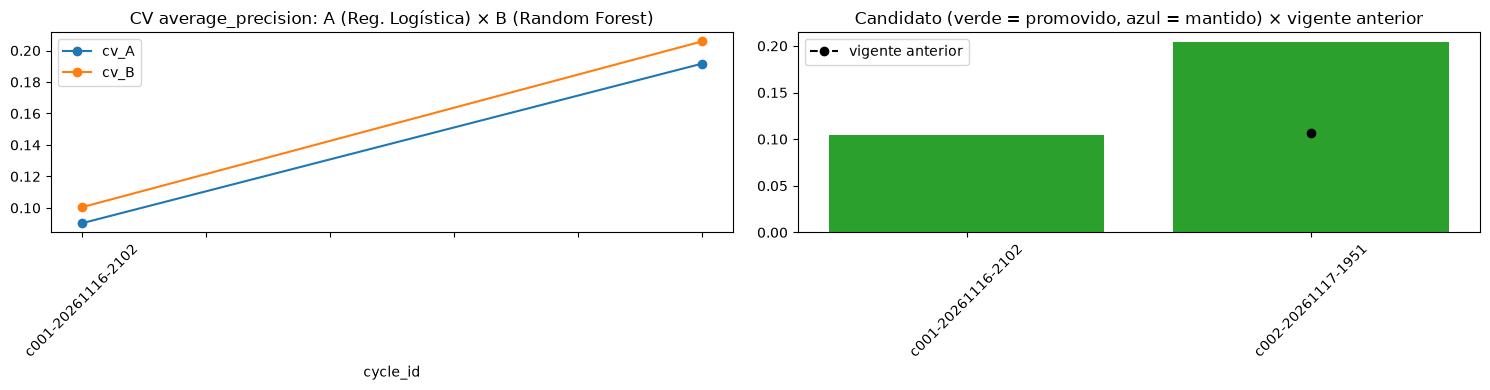

Ciclos em que o conjunto de features mudou: ['c001-20261116-2102', 'c002-20261117-1951']


In [7]:
if len(hist) > 1:
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    hist.plot(x="cycle_id", y=["cv_A", "cv_B"], marker="o", ax=ax[0], title=f"CV {metrica}: A (Reg. Logística) × B (Random Forest)")
    cores = hist["decisao"].map({"PROMOVIDO": "#2ca02c", "MANTIDO": "#1f77b4", "REJEITADO": "#d62728"})
    ax[1].bar(hist["cycle_id"], hist[f"candidato_val_{metrica}"], color=cores)
    ax[1].plot(hist["cycle_id"], hist[f"vigente_anterior_val_{metrica}"], "ko--", label="vigente anterior")
    ax[1].set_title("Candidato (verde = promovido, azul = mantido) × vigente anterior"); ax[1].legend()
    for a in ax: a.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.show()

    mudou = hist["features_eleitas"].ne(hist["features_eleitas"].shift())
    print("Ciclos em que o conjunto de features mudou:", hist.loc[mudou, "cycle_id"].tolist())

In [8]:
# Histórico consultável no MLflow: todos os runs de todos os ciclos
mlflow = configurar_mlflow(cfg)
runs = mlflow.search_runs(experiment_names=[cfg["mlflow"]["experimento"]], order_by=["start_time ASC"])
cols = [c for c in ["tags.cycle_id", "tags.etapa", "tags.data_version", "tags.gatilho", "params.algoritmo",
                    f"metrics.cv_{metrica}_media", "params.decisao", "run_id"] if c in runs.columns]
display(runs[cols].tail(20))

,tags.cycle_id,tags.etapa,tags.data_version,tags.gatilho,params.algoritmo,metrics.cv_average_precision_media,params.decisao,run_id
0,c001-20261116-2102,01_etl,v001-44df464c,schedule,NaN,NaN,NaN,d3b603e6577b4d4b9587ba59c7d64a87
1,c001-20261116-2102,02_votacao,v001-44df464c,schedule,NaN,NaN,NaN,3f50e8a7ff8e4ad385bfa397a0cdba14
2,c001-20261116-2102,03_treino,v001-44df464c,schedule,regressao_logistica,0.090226,NaN,6d093a900ae742fe886a9d2ed7012c2c
3,c001-20261116-2102,03_treino,v001-44df464c,schedule,random_forest,0.100393,NaN,62a8621e797144deabc85e1a9e4d1072
4,c001-20261116-2102,04_promocao,v001-44df464c,schedule,NaN,NaN,PROMOVIDO,1456d4163be643ec93414675f1013b68
5,c001-20261116-2102,05_previsoes,v001-44df464c,schedule,NaN,NaN,NaN,047f728bb08c455d895b386216eac520
6,c002-20261117-1951,01_etl,v002-db4f8bd6,schedule,NaN,NaN,NaN,9461e2270d314249a2c96b04db8544d4
7,c002-20261117-1951,02_votacao,v002-db4f8bd6,schedule,NaN,NaN,NaN,70adf77f35144b10937f39a68553198b
8,c002-20261117-1951,03_treino,v002-db4f8bd6,schedule,regressao_logistica,0.191662,NaN,c9cbb008e5a5489ab050024ee054c02e
9,c002-20261117-1951,03_treino,v002-db4f8bd6,schedule,random_forest,0.205791,NaN,95017d4674bf4200a7adcbc8d2fa85ce
